# Projeto End-to-End de Análise e Modelagem de Risco de Crédito

- **Repositório:** `machine-learning-portfolio`  
- **Tecnologias:** Scikit-Learn, Pandas, Seaborn  
- **Arquivo Original:** `TrabalhoDataScience.ipynb`  

---


# Final Report - Data Science
## Bachelor's Degree in Computer Science / PUCPR

**Prof. Jean Paul Barddal** / **Prof. Rayson Laroca**

Luís Felipe Yoshio Sato - luis.yoshio@pucpr.edu.br

Luiz Guilherme Durau Rodrigues - luiz.durau@pucpr.edu.br

Pedro Lunardelli Antunes - pedro.lunardelli@pucpr.edu.br

Renan Antonio Hammerschmidt Krefta - renan.krefta@pucpr.edu.br

Thiago Vinícius Pereira Borges - thiago.v@pucpr.edu.br

Victor Silva Camargo - victor.camargo1@pucpr.edu.br

Vinícius Silva Camargo - vinicius.camargo1@pucpr.edu.br

2025

# Import the libs you need

In [1]:
# Import all packages you need here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report
# import svc
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE
# etc.

# Load your data

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/Pow3rfulR2307/datasetColab/refs/heads/main/student-por.csv", sep=';')

In [3]:
#df.info()
#df.describe()
#df

In [4]:
# Para variáveis categóricas nominais
def describe_categorical(df, column):
    """
    - Contagem por categoria
    - Porcentagem por categoria
    - Moda
    """
    print(f"=-=- Estatísticas: {column} =-=-")

    counts = df[column].value_counts(dropna=False)
    print("Contagem por categoria:")
    print(counts, "\n")

    porcentagens = ((counts / counts.sum()) * 100).round(2)
    print("Porcentagem por categoria:")
    print(porcentagens.astype(str) + "%", "\n")

    print("Moda:")
    print(df[column].mode().tolist(), "\n")
    print("=-" * 15, "\n")

# Para variáveis númericas e categóricas ordinais
def describe_numeric(df, column):
    """
    - Média
    - Desvio Padrão
    - Skewness
    - Kurtosis
    """
    print(f"=-=- Estatísticas: {column} =-=-")

    values = df[column]
    mean_val = values.mean()
    std_val = values.std()
    skew_val = values.skew()
    kurt_val = values.kurt()

    print(f"Skewness: {skew_val:.2f}")
    print(f"Kurtosis: {kurt_val:.2f}")
    print(f"Média: {mean_val:.2f}")
    print(f"Desvio Padrão: {std_val:.2f}")
    print("=-" * 15, "\n")


In [5]:
# clean and treat the data here
# Remover Duplicatas
df = df.drop_duplicates()

# Ver se existe qualquer valor nulo no DataFrame
df.isnull().values.any()

np.False_

-----------

# Statistical Description

**Número de instâncias:** 649<br><br>
**Número de features:** 33<br><br>
**Número de classes:** 2<br><br>
**Distribuição de classes:**<br><br>

Aprovado = 69.33%
<br>
Reprovado = 30.66%

<br>
Em nosso caso, decidimos que as classes seriam referentes às médias anuais dos alunos, ou seja, soma das features G1, G2 e G3 ((G1+G2+G3)/3). Se um aluno tiver essa média maior que 10 consideramos que esse aluno foi "Aprovado", caso contrário, "Reprovado".<br>
Para a aplicação em machine learning, iremos remover essas colunas das notas, substituindo-as por uma única coluna de valores binários que representam essa nossa classe de aprovação ou reprovação dos alunos
<br>

In [6]:
classes_dist = df[['G1', 'G2', 'G3']].copy()
classes_dist['aprovado'] = (df['G1'] + df['G2'] + df['G3']) / 3
classes_dist = classes_dist['aprovado'].apply(lambda x: 'Aprovado' if x > 10 else 'Reprovado')

In [7]:
print((classes_dist.value_counts() / len(classes_dist)) * 100)

aprovado
Aprovado     69.337442
Reprovado    30.662558
Name: count, dtype: float64


**Descrição de Variáveis Selecionadas**

- **sex**: Indica o sexo do estudante, podendo assumir os valores `"F"` (feminino) ou `"M"` (masculino).

- **age**: Representa a idade do estudante, com valores numéricos variando de **15 a 22 anos**.

- **traveltime**: Refere-se ao tempo de deslocamento da casa até a escola, codificado da seguinte forma:
  - `1`: menos de 15 minutos  
  - `2`: entre 15 e 30 minutos  
  - `3`: entre 30 minutos e 1 hora  
  - `4`: mais de 1 hora

- **studytime**: Tempo semanal dedicado aos estudos:
  - `1`: menos de 2 horas  
  - `2`: entre 2 e 5 horas  
  - `3`: entre 5 e 10 horas  
  - `4`: mais de 10 horas

- **internet**: Indica se o estudante possui acesso à internet em casa, com os valores possíveis `"yes"` (sim) ou `"no"` (não).

- **Dalc** e **Walc**: Representam o consumo de álcool durante os dias de semana (**Dalc**) e nos fins de semana (**Walc**), com valores de:
  - `1`: muito baixo  
  - `2`: baixo  
  - `3`: médio  
  - `4`: alto  
  - `5`: muito alto

- **absences**: Número total de faltas do estudante ao longo do período letivo, variando de **0 a 93**.


---
# Univariate data analysis

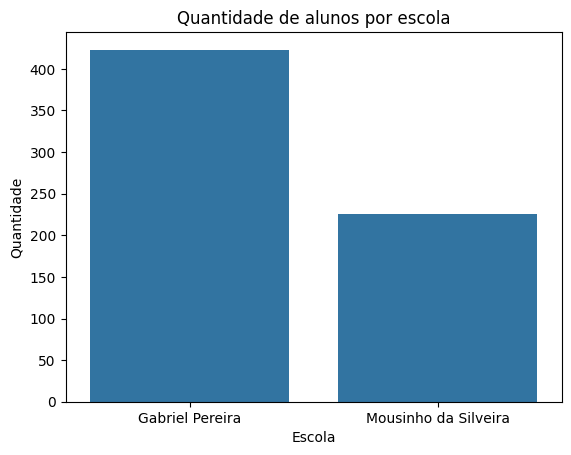

=-=- Estatísticas: school =-=-
Contagem por categoria:
school
GP    423
MS    226
Name: count, dtype: int64 

Porcentagem por categoria:
school
GP    65.18%
MS    34.82%
Name: count, dtype: object 

Moda:
['GP'] 

=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [8]:
# Variável school: Escola do estudante – "GP" (Gabriel Pereira) ou "MS" (Mousinho da Silveira)

# Qual a quantidade de alunos por escola?
sns.countplot(x="school", data=df)
plt.title("Quantidade de alunos por escola")
plt.xticks(ticks=[0, 1], labels=["Gabriel Pereira", "Mousinho da Silveira"])
plt.xlabel("Escola")
plt.ylabel("Quantidade")
plt.show()

describe_categorical(df, 'school')

**É possível perceber que o colégio Gabriel Pereira (GP) possui aproximadamente o dobro da quantidade de alunos do colégio Mousinho da Silveira (MS).**

----
<br>

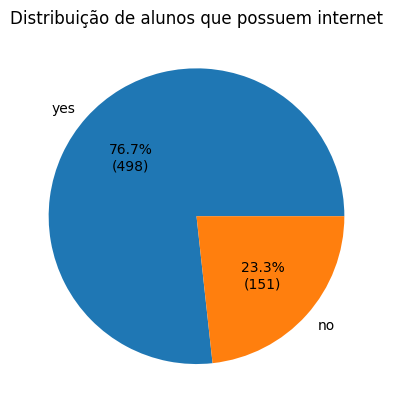

=-=- Estatísticas: internet =-=-
Contagem por categoria:
internet
yes    498
no     151
Name: count, dtype: int64 

Porcentagem por categoria:
internet
yes    76.73%
no     23.27%
Name: count, dtype: object 

Moda:
['yes'] 

=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [9]:
# Variável internet: Acesso à internet em casa – "yes" ou "no"

# Qual a porcentagem de alunos que possuem internet em casa?
def autopct_format(values):
    def my_format(pct):
        total = sum(values)
        val = int(round(pct*total/100.0))
        return '{:.1f}%\n({v:d})'.format(pct, v=val)
    return my_format

s = df['internet'].value_counts()
plt.pie(s, labels=s.index, autopct=autopct_format(s))
plt.title("Distribuição de alunos que possuem internet")
plt.show()

describe_categorical(df, 'internet')

**A quantidade de alunos que não possuem internet em casa é menor que 25% da
quantidade de alunos que participaram da pesquisa.**

----
<br>

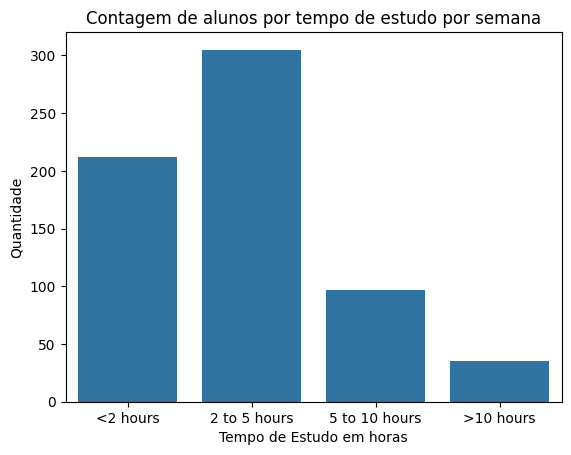

=-=- Estatísticas: studytime =-=-
Skewness: 0.70
Kurtosis: 0.04
Média: 1.93
Desvio Padrão: 0.83
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [10]:
# Variável studytime: Tempo de estudo semanal – 1: (<2 h), 2: (2–5 h), 3: (5–10 h) ou 4: (>10 h)

# Qual o tempo de estudo dos alunos em horas por semana

sns.countplot(x="studytime", data=df)
plt.title("Contagem de alunos por tempo de estudo por semana")
plt.xlabel("Tempo de Estudo em horas")
plt.xticks(ticks=["1", "2", "3", "4"], labels=["<2 hours", "2 to 5 hours", "5 to 10 hours", ">10 hours"])
plt.ylabel("Quantidade")
plt.show()

describe_numeric(df, 'studytime')

**A maior parte dos alunos, mais de 300, e quase 50% da quantidade total (649), estudam entre 2 a 5 horas por semana.**

----
<br>



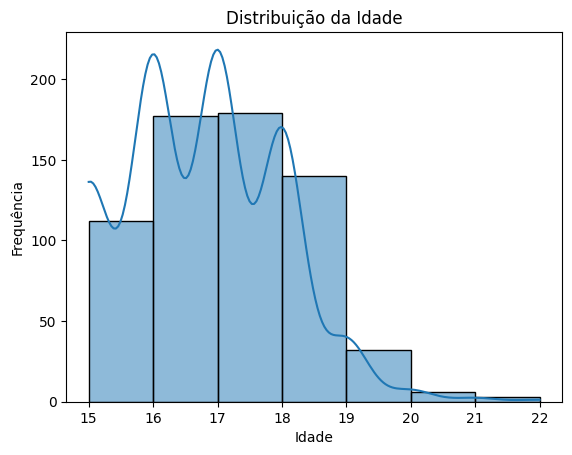

=-=- Estatísticas: age =-=-
Skewness: 0.42
Kurtosis: 0.07
Média: 16.74
Desvio Padrão: 1.22
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [11]:
# Variável age: Idade – valores de 15 a 22 anos

# Qual é a distribuição da idade dos alunos?
sns.histplot(df["age"], bins=range(15, 23), kde=True)
plt.title("Distribuição da Idade")
plt.xlabel("Idade")
plt.ylabel("Frequência")
plt.show()

describe_numeric(df, 'age')

**A grande maioria dos alunos se encontram na faixa de 16 à 18 anos de idade. Alunos com idades maiores, entre 20 a 22, podem ser alunos com "Failures", ou seja, que reprovaram em algum momento.**

---
<br>

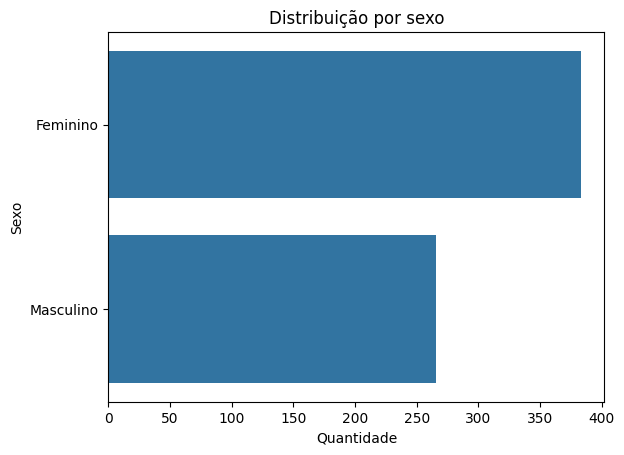

=-=- Estatísticas: sex =-=-
Contagem por categoria:
sex
F    383
M    266
Name: count, dtype: int64 

Porcentagem por categoria:
sex
F    59.01%
M    40.99%
Name: count, dtype: object 

Moda:
['F'] 

=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [12]:
# Variável sex: Sexo – "F" (feminino) ou "M" (masculino)

# Qual é a proporção entre alunos do sexo masculino e feminino?
sns.countplot(df['sex'])
plt.title("Distribuição por sexo")
plt.xlabel("Quantidade")
plt.ylabel("Sexo")
plt.yticks(ticks=["F", "M"], labels=["Feminino", "Masculino"])
plt.show()

describe_categorical(df, 'sex')

**O número de meninas é consideralvemente maior do que o de meninos. Não há evidências concretas nesse gráfico sobre o que pode causar isso.**

---
<br>

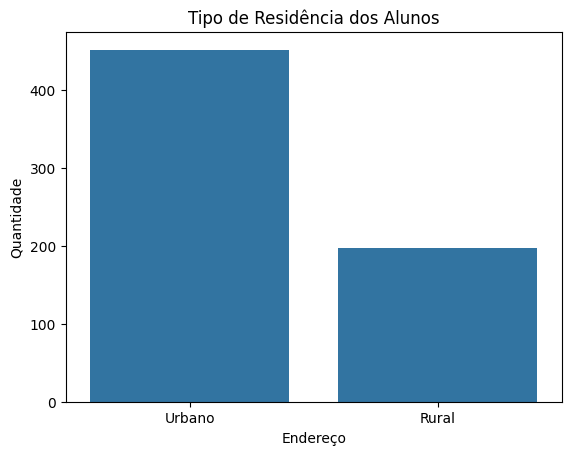

=-=- Estatísticas: address =-=-
Contagem por categoria:
address
U    452
R    197
Name: count, dtype: int64 

Porcentagem por categoria:
address
U    69.65%
R    30.35%
Name: count, dtype: object 

Moda:
['U'] 

=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [13]:
# Variável address: Endereço – "U" (urbano) ou "R" (rural)

# A maioria dos alunos vive em área urbana ou rural?
sns.countplot(x="address", data=df)
plt.title("Tipo de Residência dos Alunos")
plt.xlabel("Endereço")
plt.xticks(ticks=["U", "R"], labels=["Urbano", "Rural"])
plt.ylabel("Quantidade")
plt.show()

describe_categorical(df, 'address')

**A quantidade de alunos que mora em área rural é menor que 50%, é interessante perceber que esse número pode estar relacionado com a quantidade de alunos que não possuem internet em casa, ou com o colégio que frequentam.**


---
<br>

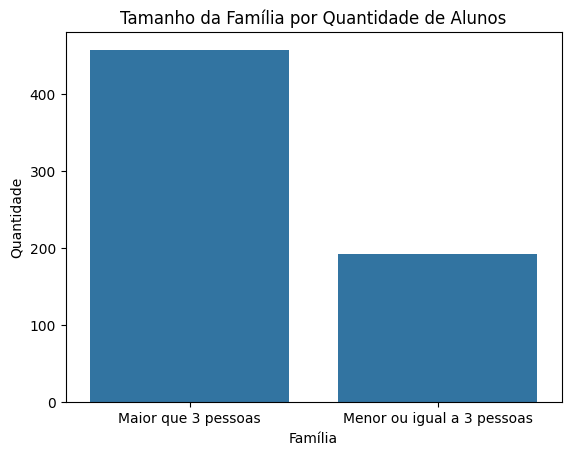

=-=- Estatísticas: famsize =-=-
Contagem por categoria:
famsize
GT3    457
LE3    192
Name: count, dtype: int64 

Porcentagem por categoria:
famsize
GT3    70.42%
LE3    29.58%
Name: count, dtype: object 

Moda:
['GT3'] 

=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [14]:
# Variável famsize: Tamanho da família – "LE3" (≤3 membros) ou "GT3" (>3 membros)

# Qual é o tamanho das famílias dos alunos?
sns.countplot(x="famsize", data=df)
plt.title("Tamanho da Família por Quantidade de Alunos")
plt.xlabel("Família")
plt.xticks(ticks=["GT3", "LE3"], labels=["Maior que 3 pessoas", "Menor ou igual a 3 pessoas"])
plt.ylabel("Quantidade")
plt.show()

describe_categorical(df, 'famsize')

**A quantidade de alunos que possuem 3 ou menos membros na famíla é menor que metade dos que possuem mais de 3 membros.**

---
<br>

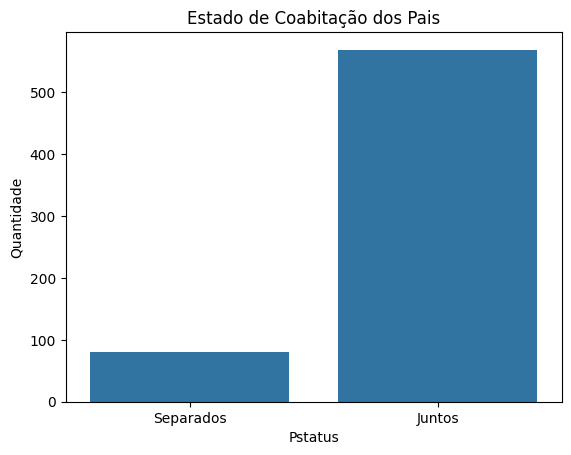

=-=- Estatísticas: Pstatus =-=-
Contagem por categoria:
Pstatus
T    569
A     80
Name: count, dtype: int64 

Porcentagem por categoria:
Pstatus
T    87.67%
A    12.33%
Name: count, dtype: object 

Moda:
['T'] 

=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [15]:
# Variável Pstatus: Convivência dos pais – "T" (juntos) ou "A" (separados)

# Os pais dos alunos vivem juntos?
sns.countplot(x="Pstatus", data=df)
plt.title("Estado de Coabitação dos Pais")
plt.xlabel("Pstatus")
plt.xticks(ticks=["T", "A"], labels=["Juntos", "Separados"])
plt.ylabel("Quantidade")
plt.show()

describe_categorical(df, 'Pstatus')

**A quantidade de alunos que possuem pais separados é consideravelmente menor que do que a quantidade de alunos que possuem pais juntos.**

---
<br>

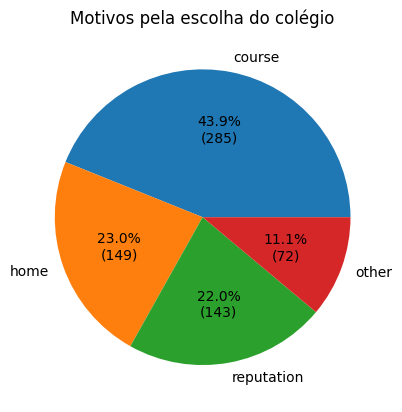

=-=- Estatísticas: reason =-=-
Contagem por categoria:
reason
course        285
home          149
reputation    143
other          72
Name: count, dtype: int64 

Porcentagem por categoria:
reason
course        43.91%
home          22.96%
reputation    22.03%
other         11.09%
Name: count, dtype: object 

Moda:
['course'] 

=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [16]:
# Variável reason: Motivo de escolha da escola – "home" (próxima de casa), "reputation", "course" (preferência pelo ensino) ou "other"

# Qual a razão de escolha nestas escolas?
def autopct_format(values):
    def my_format(pct):
        total = sum(values)
        val = int(round(pct*total/100.0))
        return '{:.1f}%\n({v:d})'.format(pct, v=val)
    return my_format

s = df['reason'].value_counts()

plt.pie(s, labels=s.index, autopct=autopct_format(s))
plt.title("Motivos pela escolha do colégio")
plt.show()

describe_categorical(df, 'reason')

**Quase metade dos estudantes usam como justificativa a "preferência do curso" para a escolha do colégio. Além disso, "reputação da escola" e "distância da casa até a escola" diferem em apenas 1%.**

---
<br>

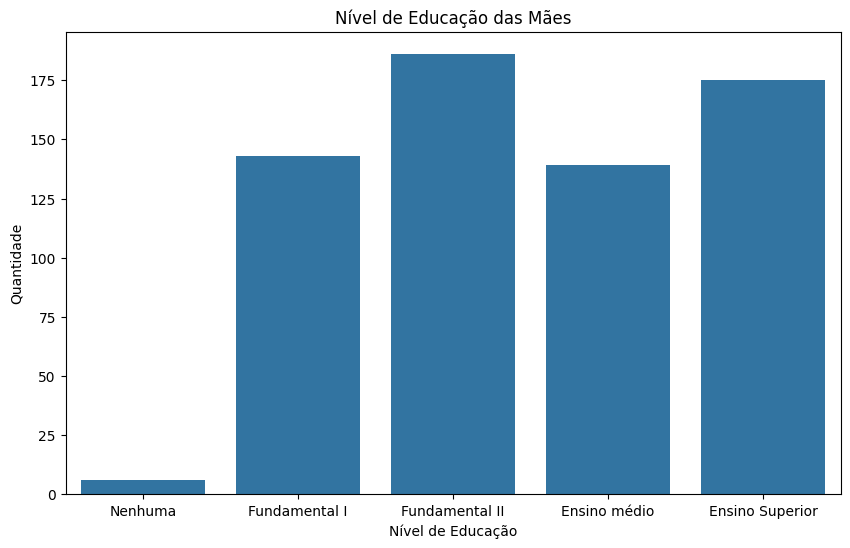

=-=- Estatísticas: Medu =-=-
Skewness: -0.03
Kurtosis: -1.26
Média: 2.51
Desvio Padrão: 1.13
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [17]:
# Variável Medu: Escolaridade da mãe – 0 (nenhum), 1 (primário), 2 (5ª a 9ª série), 3 (ensino médio) ou 4 (superior)

# Qual a escolaridade das mães?
plt.figure(figsize=(10,6))
sns.countplot(x="Medu", data=df)
plt.title("Nível de Educação das Mães")
plt.ylabel("Quantidade")
plt.xlabel("Nível de Educação")
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=["Nenhuma", "Fundamental I", "Fundamental II", "Ensino médio", "Ensino Superior"])
plt.show()

describe_numeric(df, 'Medu')


**A quantidade de alunos que possuem mães com nenhum Nível de Educação é extremamente baixa, a maioria dos alunos possuem mães com algum nível de edução. Interessante pensar que pais sem educação podem ser mais propícios a não considerarem a formação acadêmica como importante para seus filhos, portanto, não os matriculando nas escolas.**

---
<br>

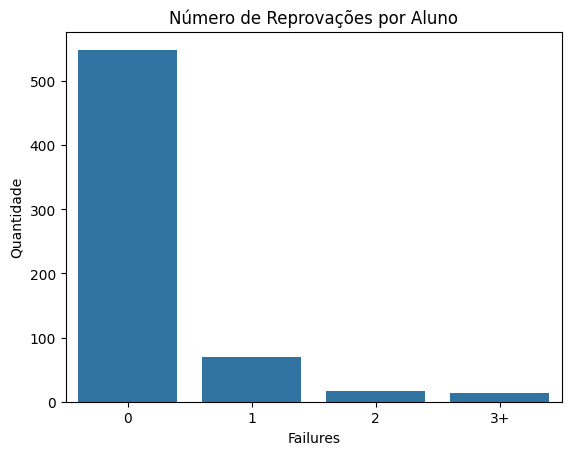

=-=- Estatísticas: failures =-=-
Skewness: 3.09
Kurtosis: 9.82
Média: 0.22
Desvio Padrão: 0.59
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [18]:
# Variável failures: Número de reprovações – valor numérico (0: 0, 1: 1, 2: 2 e 3: n≥3)

# Quantos alunos já reprovaram em disciplinas anteriores?
sns.countplot(x="failures", data=df)
plt.title("Número de Reprovações por Aluno")
plt.xlabel("Failures")
plt.ylabel("Quantidade")
plt.xticks(ticks=[0, 1, 2, 3], labels=["0", "1", "2", "3+"])
plt.show()

describe_numeric(df, 'failures')

**Muitos poucos alunos reprovaram 2 ou mais vezes. Talvez esses alunos sejam os mais velhos, o que justificaria também a baixa quantidade de alunos com mais de 19 anos, como visto anteriormente em outro gráfico.**

---
<br>

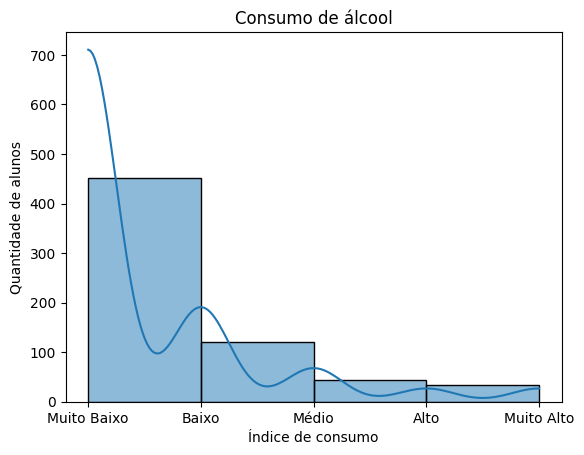

In [19]:
# Variável Dalc: Consumo de álcool nos dias úteis – escala de 1 a 5 (muito baixo, baixo, médio, alto, muito alto)

# Qual o consumo de alcool  dos alunos?
sns.histplot(df["Dalc"], bins=range(1,6), kde=True)
plt.title("Consumo de álcool")
plt.xlabel("Índice de consumo")
plt.ylabel("Quantidade de alunos")
plt.xticks([1, 2, 3, 4, 5],['Muito Baixo', 'Baixo', 'Médio', 'Alto', 'Muito Alto'])
plt.show()

**O gráfico do consumo de álcool revela que a maioria dos estudantes apresenta um padrão de consumo baixo a moderado durante os dias úteis.**

---
<br>

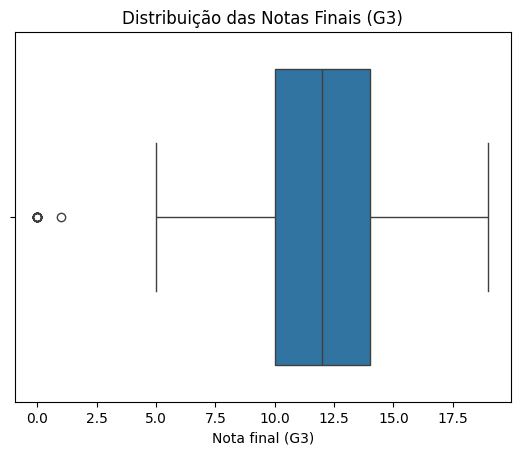

=-=- Estatísticas: G3 =-=-
Skewness: -0.91
Kurtosis: 2.71
Média: 11.91
Desvio Padrão: 3.23
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [20]:
# Variável G3: Nota final – valores de 0 a 20

# Qual a distribuição de notas finais dos alunos?
sns.boxplot(x=df['G3'])
plt.title('Distribuição das Notas Finais (G3)')
plt.xlabel('Nota final (G3)')
plt.show()

describe_numeric(df, 'G3')

**Observa-se que a maior parte das notas finais se encontra entre 10 e 14,5 aproximadamente. A mediana aparenta estar entre 12 e 12,5. Temos alguns outliers bem baixos, essas notas variam de 0 a 1 aproximadamente, provavelmente alunos que desistiram da matéria ou com muitas faltas.**

----
<br>


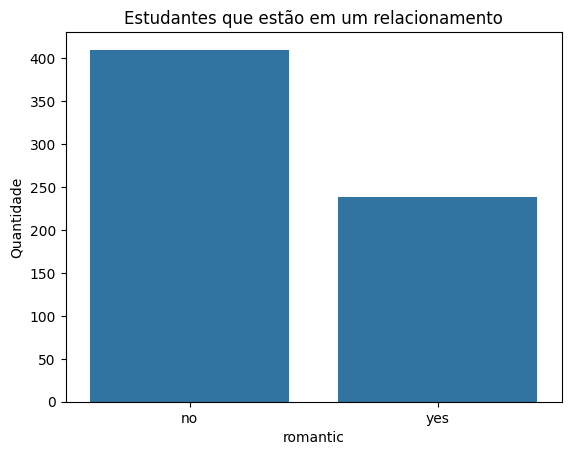

=-=- Estatísticas: romantic =-=-
Contagem por categoria:
romantic
no     410
yes    239
Name: count, dtype: int64 

Porcentagem por categoria:
romantic
no     63.17%
yes    36.83%
Name: count, dtype: object 

Moda:
['no'] 

=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [21]:
# Variável romantic: Relacionamento romântico – "yes" ou "no"

# Quantos estudantes estão em um relacionamento?
sns.countplot(x="romantic", data=df)
plt.title("Estudantes que estão em um relacionamento")
plt.ylabel("Quantidade")
plt.show()

describe_categorical(df, 'romantic')

**Mais de 60% dos alunos não estão em um relacionamento, interessante pensar se o relacionamento pode ser um fator de impacto nas falhas.**

----
<br>

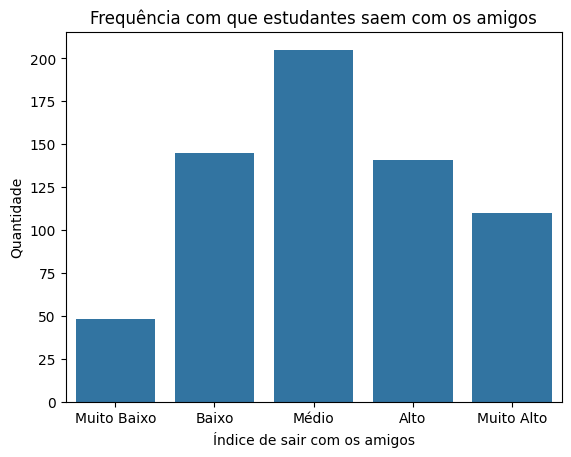

=-=- Estatísticas: goout =-=-
Skewness: -0.01
Kurtosis: -0.87
Média: 3.18
Desvio Padrão: 1.18
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [22]:
# Variável goout: Frequência de sair com amigos – escala de 1 a 5 (muito baixo, baixo, médio, alto, muito alto)

# Com qual frequência os estudantes saem com os amigos?
sns.countplot(x="goout", data=df)
plt.title("Frequência com que estudantes saem com os amigos")
plt.xlabel("Índice de sair com os amigos")
plt.xticks([0, 1, 2, 3, 4],['Muito Baixo', 'Baixo', 'Médio', 'Alto', 'Muito Alto'])
plt.ylabel("Quantidade")
plt.show()

describe_numeric(df, 'goout')

**A média se encontra em torno de 3, a maior parte dos alunos saem com os amigos com uma boa frequência. Fazendo um parelelo, como a grande maioria dos alunos não reprovaram nenhuma vez, é possível que essa feature não tenha tanto impacto nas notas finais, mas ainda não é possível ter certeza.**

---
<br>

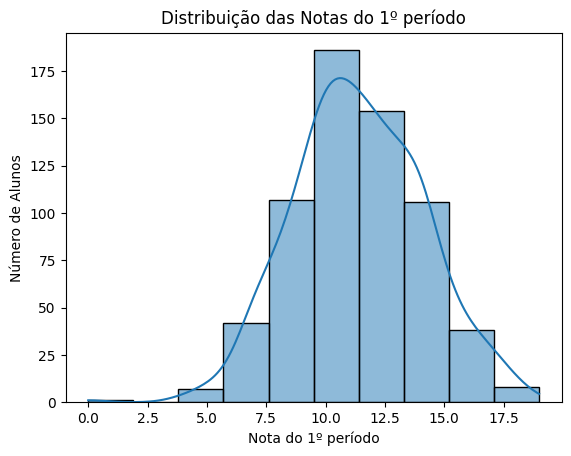

=-=- Estatísticas: G1 =-=-
Skewness: -0.00
Kurtosis: 0.04
Média: 11.40
Desvio Padrão: 2.75
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [23]:
# Variável G1: Nota do 1º período – valores de 0 a 20.

# Qual a distribuição de notas do 1º período?
sns.histplot(df['G1'], bins=10, kde=True)
plt.title('Distribuição das Notas do 1º período')
plt.xlabel('Nota do 1º período')
plt.ylabel('Número de Alunos')
plt.show()

describe_numeric(df, 'G1')

**Pela distribuição das notas do 1º período, percebe-se que a maioria dos alunos está em uma faixa próxima à média, sem concentrações extremas de notas baixas ou máximas. Esse resultado sugere que a maior parte dos estudantes atinge um nível satisfatório, ainda que haja espaço para melhorar ou buscar notas mais elevadas.**

---
<br>

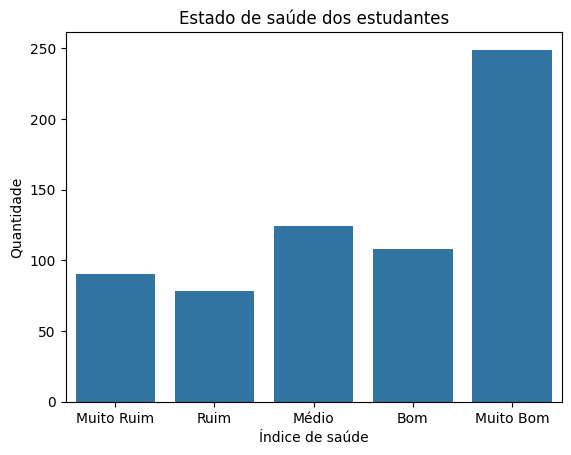

=-=- Estatísticas: health =-=-
Skewness: -0.50
Kurtosis: -1.12
Média: 3.54
Desvio Padrão: 1.45
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [24]:
# Variável health: Estado de saúde atual – escala de 1 a 5 (muito ruim, ruim, médio, bom, muito bom)

# Qual o estado de saúde dos estudantes?
sns.countplot(x="health", data=df)
plt.title("Estado de saúde dos estudantes")
plt.xlabel("Índice de saúde")
plt.xticks([0, 1, 2, 3, 4],['Muito Ruim', 'Ruim', 'Médio', 'Bom', 'Muito Bom'])
plt.ylabel("Quantidade")
plt.show()

describe_numeric(df, 'health')

**Com uma média em torno de 3, é possível concluir que os alunos geralmente tem uma saúde boa. Contudo, uma boa parte ainda possui saúde comprometida. Como esse número chega a ser um pouco alto, apesar de ser menor que a média, as métricas usadas para a medição de saúde podem ter incluído problemas como depressão e ansiedade, que são problemas mais comuns nas sociedades atuais, principalmente em jovens.**

---
<br>

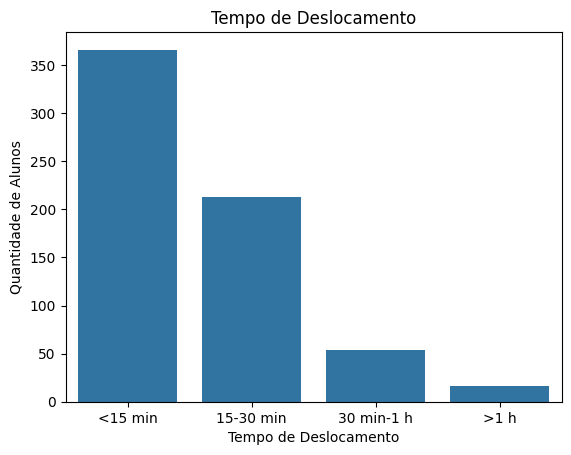

=-=- Estatísticas: traveltime =-=-
Skewness: 1.25
Kurtosis: 1.11
Média: 1.57
Desvio Padrão: 0.75
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [25]:
# Variável traveltime: Tempo de deslocamento – 1 (<15 min), 2 (15–30 min), 3 (30 min–1 h) ou 4 (>1 h)

# Qual o tempo que o estudante leva para chegar no colégio?
sns.countplot(x="traveltime", data=df)
plt.title("Tempo de Deslocamento")
plt.xlabel("Tempo de Deslocamento")
plt.xticks([0, 1, 2, 3],['<15 min', '15-30 min', '30 min-1 h', '>1 h'])
plt.ylabel("Quantidade de Alunos")
plt.show()

describe_numeric(df, 'traveltime')

**A grande maioria dos alunos mora relativamente perto da escola. Talvez alunos que demorem mais tempo morem em regiões mais afastadas, ou dependem de meios de transporte mais lento como ônibus. Como visto anteriormente, a maioria dos alunos moram em espaços urbanos, indo de acordo com nossa análise de tempo de deslocamento.**

---
<br>


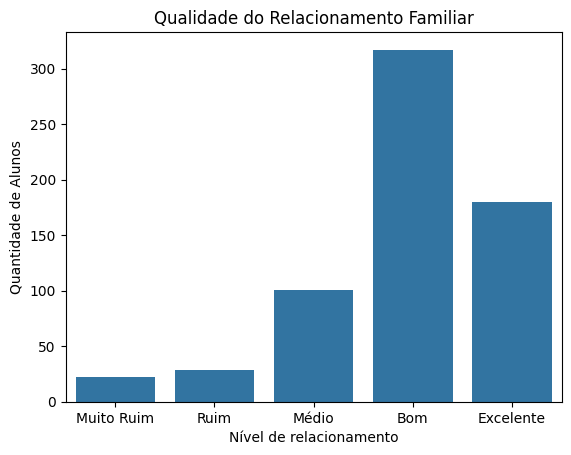

=-=- Estatísticas: famrel =-=-
Skewness: -1.11
Kurtosis: 1.35
Média: 3.93
Desvio Padrão: 0.96
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [26]:
# Variável famrel: Qualidade do relacionamento familiar – escala de 1 a 5 (muito ruim, ruim, médio, bom, excelente)

# Como é o relacionamento familiar nas casas dos alunos?
sns.countplot(x="famrel", data=df)
plt.title("Qualidade do Relacionamento Familiar")
plt.xlabel("Nível de relacionamento")
plt.xticks([0, 1, 2, 3, 4],['Muito Ruim', 'Ruim', 'Médio', 'Bom', 'Excelente'])
plt.ylabel("Quantidade de Alunos")
plt.show()

describe_numeric(df, 'famrel')

**Com uma média em torno de 4, fica claro que apesar de ser geralmente bom, muitos alunos possuem uma relação complicada com os país ou irmãos. Pode ser um indicativo também de nossa análise da saúde dos estudantes no quesito da saúde mental, entretanto, não há evidências suficientes ainda para comprovar isso.**

---
<br>

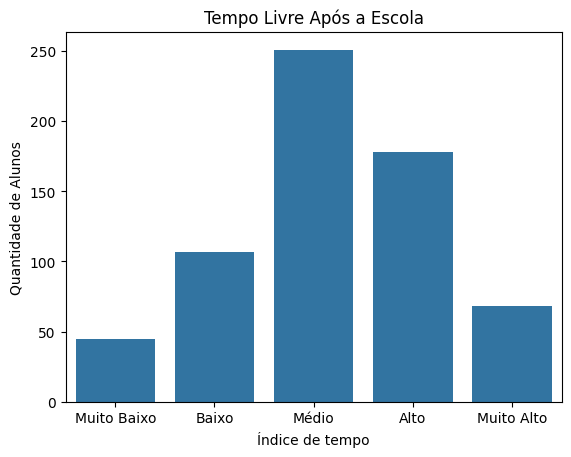

=-=- Estatísticas: freetime =-=-
Skewness: -0.18
Kurtosis: -0.40
Média: 3.18
Desvio Padrão: 1.05
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [27]:
# Variável freetime: Tempo livre – escala de 1 a 5 (muito baixo, baixo, médio, alto, muito alto)

# Quanto de tempo livre os alunos tem após a aula?
sns.countplot(x="freetime", data=df)
plt.title("Tempo Livre Após a Escola")
plt.xlabel("Índice de tempo")
plt.xticks([0, 1, 2, 3, 4],['Muito Baixo', 'Baixo', 'Médio', 'Alto', 'Muito Alto'])
plt.ylabel("Quantidade de Alunos")
plt.show()

describe_numeric(df, 'freetime')

**A maioria dos alunos possuem um tempo livre médio-alto após a escola. Contudo, como visto anteriormente, a maior parte dos alunos estuda até 5 horas por semana, evidenciando uma possível falta de comprometimento com as atividades acadêmicas. Alguns alunos com pouco tempo livre, no gráfico nos mostrando menos que 50, possam ser aqueles que demoram mais tempo para se deslocar da escola para a casa.**

---
<br>

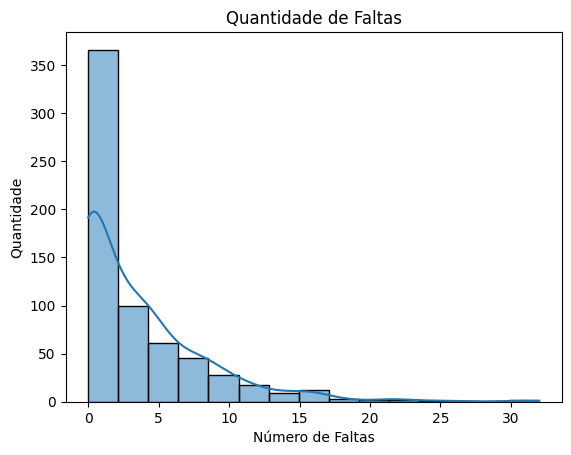

=-=- Estatísticas: absences =-=-
Skewness: 2.02
Kurtosis: 5.78
Média: 3.66
Desvio Padrão: 4.64
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=- 



In [28]:
# Variável absences: Número de faltas – valores de 0 a 93

# Qual a quantidade de faltas dos alunos?
sns.histplot(df["absences"], bins=15, kde=True)
plt.title("Quantidade de Faltas")
plt.xlabel("Número de Faltas")
plt.ylabel("Quantidade")
plt.show()

describe_numeric(df, 'absences')

**A maioria dos alunos tem poucas faltas, concentrando-se entre 0 e 5 ausências. Com poucos casos de alunos que faltaram muito. A média de aproximadamente 3 faltas indica que faltas elevadas são exceções. A maioria dos alunos mantêm uma boa frequência nas aulas.**

---
<br>

# Multivariate data analysis

**Hipótese:** A proporção de alunos com acesso à internet em casa é superior na
escola Gabriel Pereira.
<br><br>**Variáveis:** Escolhemos as variáveis de internet e escola (school). A presença de internet na moradia pode nos indicar as condições socioeconômicas dos alunos.<br><br>**Expectativas:** Esperamos que a análise ajude na melhor compreensão da hipótese, precisamos de algum valor de destaque que possa tornar o resultado quase inquestionável.


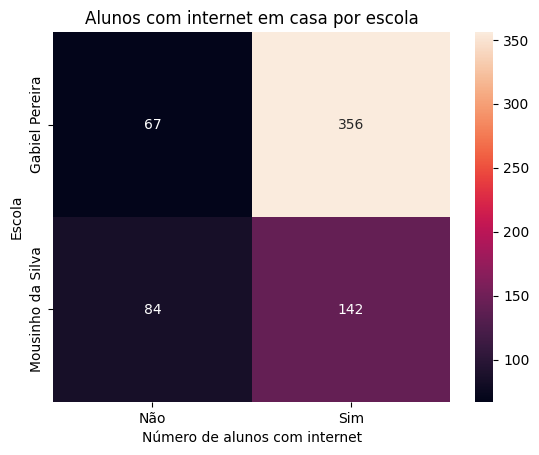

In [29]:
ctab = pd.crosstab(df['school'], df['internet'])

sns.heatmap(ctab, annot=True, fmt='d')
plt.title("Alunos com internet em casa por escola")
plt.xlabel("Número de alunos com internet")
plt.ylabel("Escola")
plt.yticks([0.5, 1.5],['Gabiel Pereira', 'Mousinho da Silva'])
plt.xticks([0.5, 1.5],['Não', 'Sim'])
plt.show()

**Aqui temos uma análise interessante, a quantidade de alunos que não possuem internet em casa e que estudam no colégio MS, é quase 40% da quantidade de alunos entrevistados do mesmo colégio, em contraste com o colégio GP, em que esse mesmo número é menor que 20%. Pode ser que o colégio MS seja mais direcionado para uma faixa demográfica de alunos de menor renda, ou pode ser que esse colégio seja localizado em uma região mais afastada, atraindo alunos que moram em regiões mais remotas onde o acesso à internet pode ser limitado.
<br><br>
Acreditamos que foi possível extrair informações suficientes para confirmar ossa hipótese de haver uma diferença demográfica.**



---

**Hipótese:** Alunos com maiores níveis de consumo de álcool em dias úteis da semana tendem a faltar mais nas aulas.
<br><br>**Variáveis:** Escolhemos as variáveis de consumo de álcool em dias de semana (Dalc), número de faltas (absences) e sexo (sex).<br><br>**Expectativas:** Esperamos que os resultados nos mostrem que quanto maior o consumo de álcool, maior serão o número de faltas. Também achamos pertinente separar por sexo para ganhar insights mais detalhados

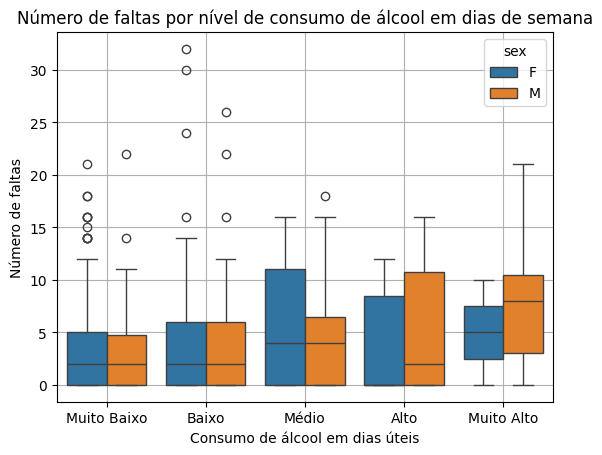

In [30]:
sns.boxplot(x=df['Dalc'], y=df['absences'], hue=df['sex'])
plt.grid(True)
plt.title("Número de faltas por nível de consumo de álcool em dias de semana")
plt.xlabel("Consumo de álcool em dias úteis")
plt.ylabel("Número de faltas")
plt.xticks([0, 1, 2, 3, 4],['Muito Baixo', 'Baixo', 'Médio', 'Alto', 'Muito Alto'])
plt.show()

**É possível perceber que não há necessariamente uma relação tão forte do consumo de álcool em dias de semana com o número de faltas como esperávamos. Contudo, até um consumo moderado(representado como médio no gráfico), começamos a perceber um número de faltas maior. Há alguns outliers interessantes quando o consumo de álcool é inferior, alguns alunos acabam faltando mais do que a maioria nas categorias de consumo mais baixas. Outro ponto interessante é de que até um consumo moderado, as meninas lideram ou estão no mesmo nível de faltas que os meninos.
<br><br>
Entretanto, com o aumento do consumo de álcool, os meninos tendem à faltar mais que as meninas. Os outliers também somem, o que indica que deixamos de ter alunos com uma discrepância fora do normal de faltas, ao mesmo tempo que támbem tivemos um aumento nos limites superiores (Q3+1,5×IQR), e começamos a visualizar os limites inferiores (Q1-1,5×IQR).**


---

**Hipótese:** Há diferença no desempenho inicial (nota G1) entre as escolas GP e MS.

<br>**Variáveis:** Escolhemos as variáveis de G1 (nota do primeiro período) e school (GP ou MS). A nota G1 serve como indicador inicial de desempenho acadêmico; já a escola permite identificar eventuais diferenças de método de ensino ou perfil comportamental dos alunos.

<br>**Expectativas:** Esperamos que a análise traga uma comparação objetiva das distribuições de notas entre as duas instituições. Se houver uma diferença marcante em determinado nível de notas (baixa, média ou alta), isso pode revelar disparidades no processo de aprendizagem ou recursos disponíveis em cada escola.


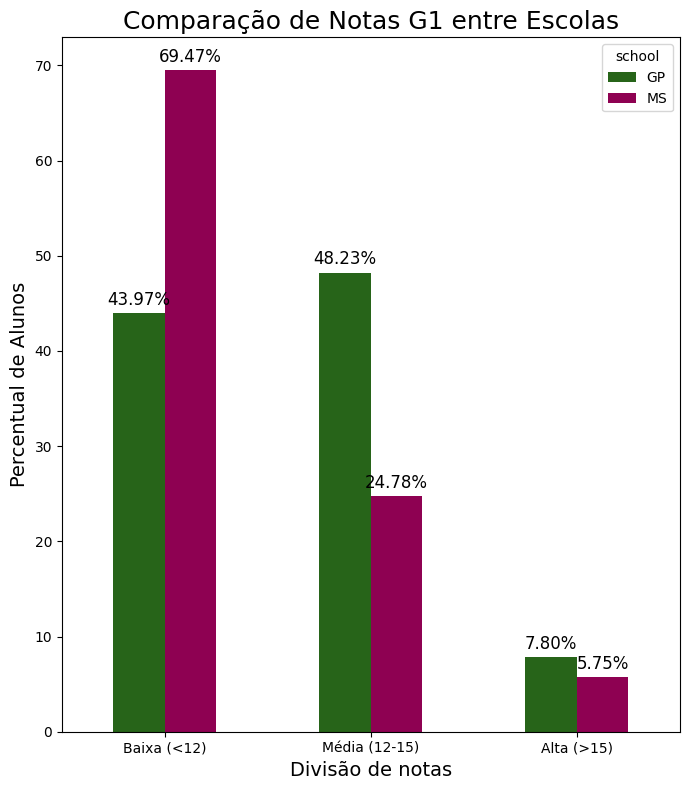

In [31]:
def convert_g1(value):
    if value < 12:
        return "Baixa (<12)"
    elif value >= 12 and value <= 15:
        return "Média (12-15)"
    else:
        return "Alta (>15)"

crosstab_g1 = pd.crosstab(index=df["G1"].apply(convert_g1),columns=df["school"])
crosstab_g1 = crosstab_g1.reindex(["Baixa (<12)", "Média (12-15)", "Alta (>15)"])

# Converte os valores para porcentagem por coluna (school), para que a quantidade de alunos das escolas não interfiram na comparação
crosstab_g1_perc = crosstab_g1.apply(lambda col: col / col.sum() * 100)

ax = crosstab_g1_perc.plot.bar(colormap="PiYG_r", figsize=(7,8))

plt.title("Comparação de Notas G1 entre Escolas", fontsize=18)
plt.ylabel("Percentual de Alunos", fontsize=14)
plt.xlabel("Divisão de notas", fontsize=14)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', label_type='edge', padding=3, fontsize=12)

plt.tight_layout()
plt.show()

**Aqui temos uma análise interessante: a proporção de alunos da escola MS com notas baixas (<12) atinge cerca de 69%, enquanto na escola GP esse número é de 44%. Já na faixa média (12–15), a escola GP tem 48% dos alunos, enquanto a MS conta com 25%. Embora ambas as instituições apresentem um pequeno percentual de alunos com notas altas (>15), a GP apresenta um ligeiro destaque (0,08% vs. 0,06%).
<br><br>
Esses resultados podem indicar que a escola MS concentra mais alunos com dificuldade no primeiro período, enquanto a GP possui um número maior de alunos que se situam no patamar intermediário de rendimento — próximos a avançar para um nível mais elevado. É plausível que fatores como estrutura pedagógica, engajamento familiar ou localização geográfica influenciem essas diferenças. Acreditamos que tais resultados reforçam nossa hipótese de existir, uma disparidade de desempenho inicial (G1) entre as duas escolas.**

---

**Hipótese:** O fato de um aluno estar em um relacionamento romântico afeta sua frequência de sair com amigos.

<br>**Variáveis:** Escolhemos as variáveis de frequência de sair (goout) e status de relacionamento (romantic). A primeira nos indica o quão frequentemente o aluno sai com amigos, enquanto a segunda nos diz se o aluno está ou não em um relacionamento.

<br>**Expectativas:** Nosso palpite é de que alunos sem relacionamento podem sair com mais frequência, pois possivelmente têm mais tempo livre ou buscam mais interação social. Em contrapartida, alunos em relacionamento podem sair menos ou redistribuir o tempo livre com o(a) parceiro(a), embora a correlação não seja necessariamente óbvia.




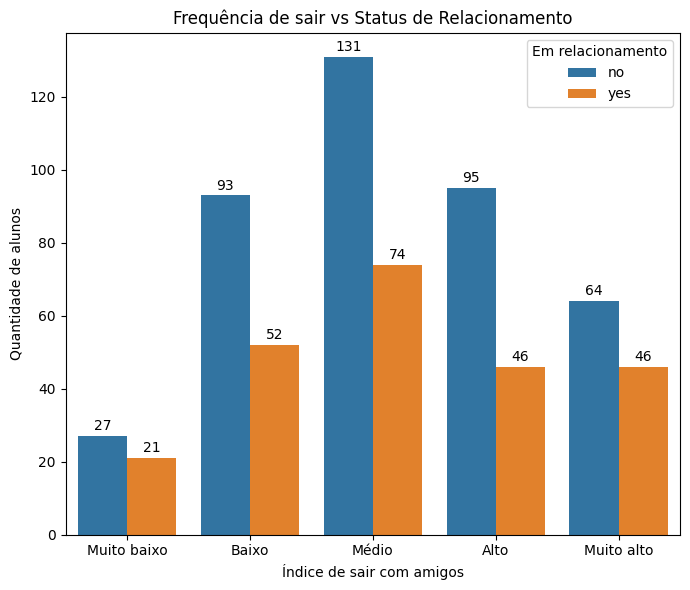

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 6))

ax = sns.countplot(x='goout', hue='romantic', data=df)

plt.title('Frequência de sair vs Status de Relacionamento')
plt.xlabel('Índice de sair com amigos')
plt.ylabel('Quantidade de alunos')
plt.legend(title='Em relacionamento')

plt.xticks(
    ticks=[0, 1, 2, 3, 4],
    labels=['Muito baixo', 'Baixo', 'Médio', 'Alto', 'Muito alto']
)

for container in ax.containers:
    ax.bar_label(container, label_type='edge', padding=2)

plt.tight_layout()
plt.show()


**Analisando o gráfico, vemos que em todas as faixas de saída com amigos há mais alunos que não estão em um relacionamento do que alunos que estão em um relacionamento. O maior contingente aparece no nível médio, com 131 alunos “sem relacionamento” e 74 “em relacionamento”. Embora esse padrão possa sugerir que quem não está em um relacionamento tende a sair com amigos em maior quantidade, também precisamos considerar que o grupo de “sem relacionamento” pode simplesmente ser maior na amostra total.
<br><br>
Esses resultados reforçam a hipótese inicial: o status de relacionamento parece influenciar, a frequência de sair com amigos. No entanto, a distribuição guarda similaridades em termos de tendência geral (picos em médio e alto). É possível que, independente de ter ou não um parceiro, a maioria dos alunos tenda a sair em uma frequência considerada mediana ou levemente alta, indicando que os hábitos de socialização tenham múltiplos fatores além do relacionamento romântico.**

---
<br>

**Hipótese:** O consumo de alcool nos dias e finais de semana influienciam no desempenho acadêmico dos alunos.

<br>**Variáveis:** As variaveis escolhidas foram o Dalc, Walc e G3, que representam o consumo de alcool nos dias de semana, finais de semana, e nota do exame final respectivamente

<br>**Expectativas:** A expectativa é de vizualizar o consumo de alcool em excesso decair o desempenho acadêmico dos estudantes, uma vez que beber muito alcool diminui as funções cognitivas do corpo humano, atrapalhando nos estudos

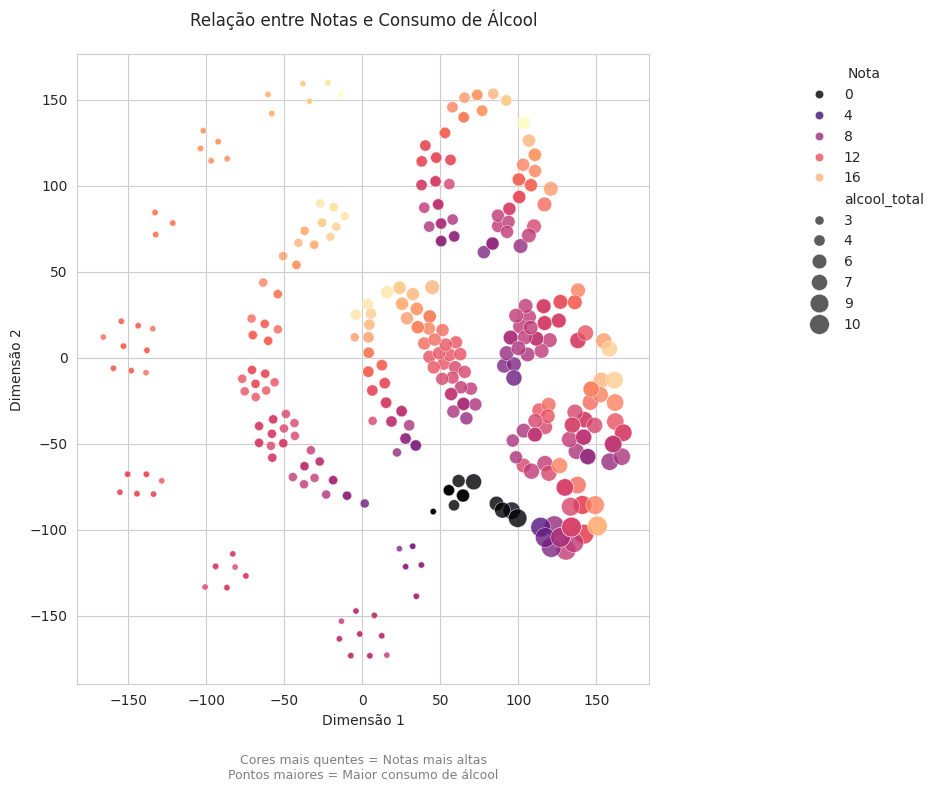

In [33]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

features = df[['Dalc', 'Walc', 'G3']].copy()
features['alcool_total'] = df['Dalc'] + df['Walc']


scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_result = tsne.fit_transform(scaled_features)

tsne_df = pd.DataFrame(tsne_result, columns=['Dim1', 'Dim2'])
tsne_df['G3'] = df['G3']
tsne_df['alcool_total'] = features['alcool_total']

plt.figure(figsize=(10, 8))
sns.set_style("whitegrid")


scatter = sns.scatterplot(
    x='Dim1',
    y='Dim2',
    hue='G3',
    size='alcool_total',
    sizes=(20, 200),
    alpha=0.8,
    palette='magma',
    data=tsne_df,
    legend='brief'
)

plt.title('Relação entre Notas e Consumo de Álcool', pad=20)
plt.xlabel('Dimensão 1', fontsize=10)
plt.ylabel('Dimensão 2', fontsize=10)

handles, labels = scatter.get_legend_handles_labels()
plt.legend(
    handles[1:],
    labels[1:],
    title='Nota',
    bbox_to_anchor=(1.25, 1),
    loc='upper left',
    frameon=False
)

plt.annotate(
    'Cores mais quentes = Notas mais altas\nPontos maiores = Maior consumo de álcool',
    xy=(0.5, -0.15),
    xycoords='axes fraction',
    ha='center',
    fontsize=9,
    color='gray'
)

plt.tight_layout()
plt.show()

**O gráfico mostra que os alunos que bebem mais álcool (pontos grandes) geralmente têm notas mais baixas (azul/roxo), especialmente na parte de baixo à direita. Já os que bebem menos (pontos pequenos) tendem a tirar notas mais altas (amarelo/laranja), principalmente na parte de cima. Isso indica que existe uma relação entre beber muito e notas ruins. No entanto, é importante lembrar que outros fatores (como estudo, motivação ou ambiente familiar) também podem influenciar esses resultados.**

---


# Final Plots (Effective Data Visualization)

In this section, you need to **enhance 3 multivariate visualizations** that were presented in the previous section of the report.
The goal is to enhance these visualizations so that they can be effectively presented to an audience unfamiliar with the dataset or with data analysis.
**Therefore, make sure that their size, colors, textures, and other visual elements are appropriate and convey the intended information to the audience.**

For your final plots, make sure you follow these steps:
1. Present the plot;
2. Provide a description of the visualization, highlighting the key findings that can be drawn from it.


**Hint**: take a look at the checklist based on Evergreen’s work to ensure your visualizations meet the best practices for clarity and impact.

/tmp/ipython-input-34-3792273670.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  media_notas = df['G3'].groupby(faixas_consumo).mean().reset_index()
/tmp/ipython-input-34-3792273670.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


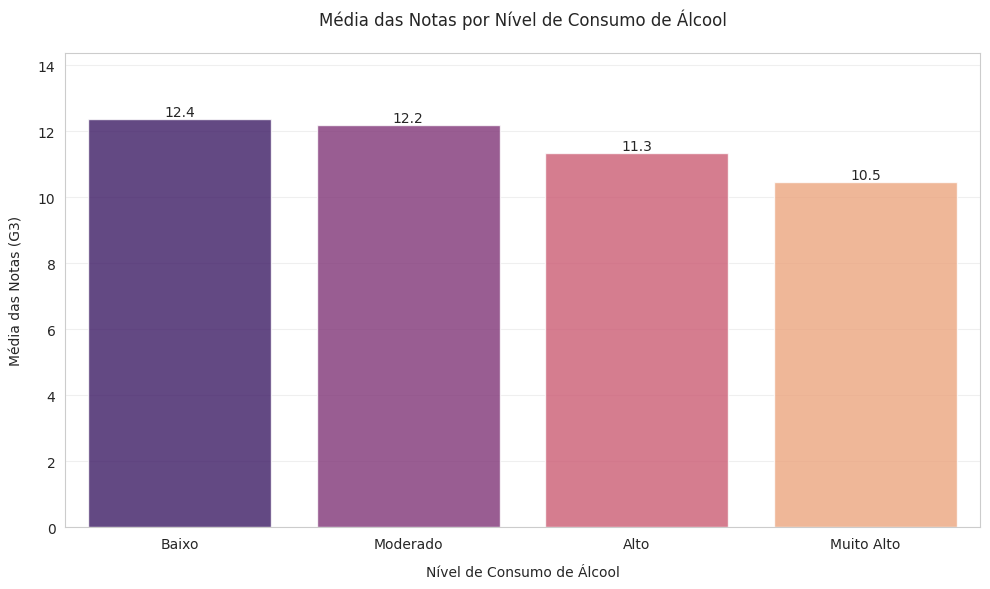

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df['alcool_total'] = df['Dalc'] + df['Walc']

faixas_consumo = pd.cut(
    df['alcool_total'],
    bins=[0, 2, 4, 6, 10],
    labels=['Baixo', 'Moderado', 'Alto', 'Muito Alto']
)

media_notas = df['G3'].groupby(faixas_consumo).mean().reset_index()
media_notas.columns = ['Nível de Consumo', 'Média das Notas']

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Nível de Consumo',
    y='Média das Notas',
    data=media_notas,
    palette='magma',
    alpha=0.8,
    order=['Baixo', 'Moderado', 'Alto', 'Muito Alto']
)

for index, row in media_notas.iterrows():
    plt.text(
        x=index,
        y=row['Média das Notas'] + 0.1,
        s=f"{row['Média das Notas']:.1f}",
        ha='center',
        fontsize=10
    )


plt.title('Média das Notas por Nível de Consumo de Álcool', pad=20)
plt.xlabel('Nível de Consumo de Álcool', labelpad=10)
plt.ylabel('Média das Notas (G3)', labelpad=10)
plt.ylim(0, media_notas['Média das Notas'].max() + 2)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

**O gráfico de barras apresenta a relação entre o consumo médio de álcool (durante a semana e aos finais de semana) e a média das notas finais dos alunos. A visualização revela uma tendência clara: quanto maior o consumo de álcool, menor tende a ser a nota final. Isso sugere que o aumento no consumo de bebidas alcoólicas pode estar associado a um desempenho escolar mais baixo.**

---
<br>

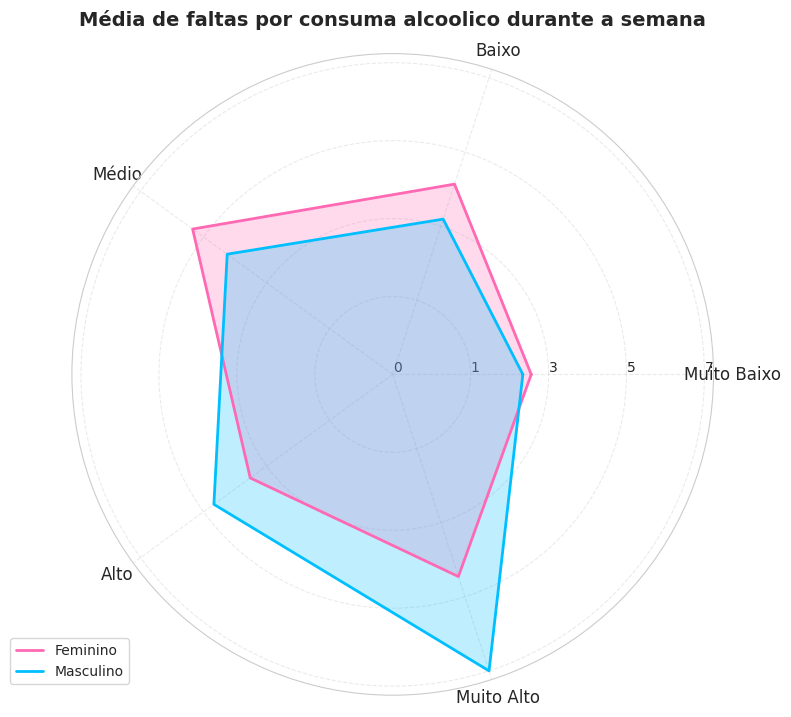

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def create_auto_radar_chart(df, title):
    dalc_values = sorted(df['Dalc'].unique())
    labels_map = {
        1: 'Muito Baixo',
        2: 'Baixo',
        3: 'Médio',
        4: 'Alto',
        5: 'Muito Alto',
    }
    labels = [labels_map[val] for val in dalc_values]
    num_vars = len(dalc_values)


    # Ângulos para o radar
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]  # Fecha o círculo

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # Valores por sexo
    def get_values(sex):
        values = (
            df[df['sex'] == sex]
            .groupby('Dalc')['absences']
            .mean()
            .reindex(dalc_values)
            .fillna(0)
            .tolist()
        )
        return values + values[:1]

    values_female = get_values('F')
    values_male = get_values('M')

    # Plot feminino
    ax.plot(angles, values_female, color='hotpink', linewidth=2, label='Feminino')
    ax.fill(angles, values_female, color='hotpink', alpha=0.25)

    # Plot masculino
    ax.plot(angles, values_male, color='deepskyblue', linewidth=2, label='Masculino')
    ax.fill(angles, values_male, color='deepskyblue', alpha=0.25)

    # Configurações do gráfico
    ax.set_thetagrids(np.degrees(angles[:-1]), labels, fontsize=12)

    max_val = np.nanmax(values_female + values_male)
    step = max_val / 4 if max_val > 0 else 1
    yticks = np.arange(0, max_val + step, step) if step > 0 else [0, 1, 2, 3, 4]
    ax.set_yticks(yticks)
    ax.set_yticklabels([f'{int(v)}' for v in yticks], fontsize=10)
    ax.set_rlabel_position(0)

    ax.set_title(title, fontsize=14, weight='bold', pad=20)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.spines['polar'].set_visible(True)
    ax.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))

    plt.tight_layout()
    plt.show()

# Executa com o título
create_auto_radar_chart(df, "Média de faltas por consuma alcoolico durante a semana")



O gráfico apresentado é um gráfico de radar que ilustra a média de faltas escolares entre estudantes com diferentes níveis de consumo de álcool durante a semana (Dalc), separados por sexo (feminino e masculino).

Essa diferença de padrões entre os gêneros sugere que o impacto do consumo de álcool sobre a frequência escolar pode variar de forma significativa entre meninos e meninas. Para os meninos, quanto maior o consumo, maior a tendência de faltar às aulas. Para as meninas, essa relação não é tão clara e pode ser influenciada por outros fatores.

----
<br>

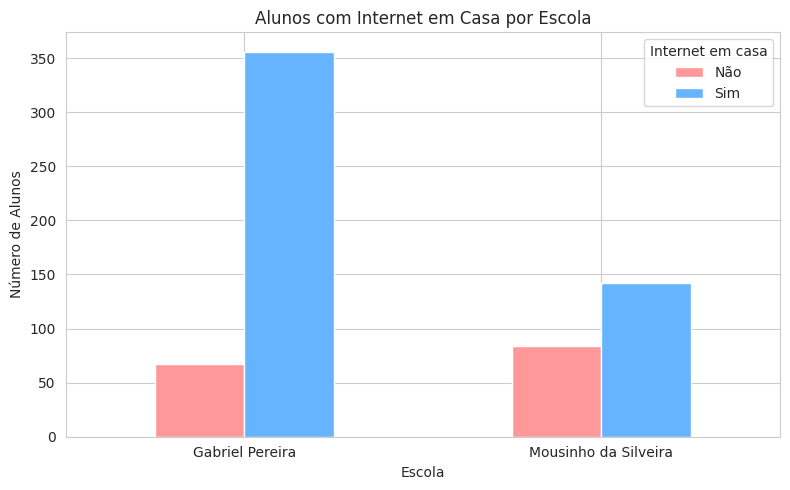

In [36]:
ctab = pd.crosstab(df['school'], df['internet'])

# Redefinindo nomes das escolas
ctab.index = ['Gabriel Pereira', 'Mousinho da Silveira']
ctab.columns = ['Não', 'Sim']

# Gráfico de barras agrupadas
ctab.plot(kind='bar', figsize=(8, 5), color=['#ff9999','#66b3ff'])

plt.title('Alunos com Internet em Casa por Escola')
plt.xlabel('Escola')
plt.ylabel('Número de Alunos')
plt.xticks(rotation=0)
plt.legend(title='Internet em casa')
plt.tight_layout()
plt.show()


O gráfico de barras apresentado mostra a quantidade de alunos que têm ou não acesso à internet em casa, separados por escola: Gabriel Pereira e Mousinho da Silveira. As barras estão agrupadas por escola e categorizadas por "Sim" (possuem internet) e "Não" (não possuem internet). As cores azul e vermelho foram utilizadas para facilitar a distinção visual.

----
<br>

# Digest


Durante o desenvolvimento deste trabalho de Data Science, aplicamos diversos conhecimentos adquiridos ao longo da disciplina, desde o pré-processamento de dados até a criação de visualizações que nos ajudaram a interpretar padrões e tendências presentes no conjunto de dados. O projeto teve como foco a análise de dados educacionais, permitindo observar como fatores pessoais, familiares e escolares se relacionam com o desempenho acadêmico dos estudantes.

Um dos primeiros pontos que vimos foi a distribuição etária dos alunos, concentrada principalmente entre 16 e 18 anos, faixa típica do ensino médio. Essa informação, obtida por meio de histogramas, ajudou a entender melhor o perfil predominante dos estudantes. Além disso, notamos diferenças significativas entre as duas escolas analisadas, tanto em relação à quantidade de alunos quanto ao contexto socioeconômico. Por exemplo, observamos que estudantes da escola Gabriel Pereira, localizada em área urbana, tendiam a ter maior acesso à internet em casa do que os da escola Mousinho da Silveira, que possui mais alunos de áreas rurais.

Durante a análise, também exploramos fatores como o consumo de álcool, tempo de estudo, estrutura familiar e hábitos sociais. Notamos, por exemplo, que alunos com maior consumo de álcool, especialmente durante a semana, apresentavam, em média, mais faltas escolares. Ainda que essa relação não implique necessariamente causalidade, ela aponta para possíveis influências comportamentais no desempenho. Da mesma forma, percebemos que alunos com tempo de estudo moderado, entre duas e cinco horas semanais, tendiam a apresentar melhores notas finais do que aqueles que estudavam muito pouco ou excessivamente. Isso reflete sobre a importância do equilíbrio entre estudo, lazer e outras responsabilidades.

O uso de gráficos como boxplots, gráficos de barras, mapas de calor e gráficos de densidade foram usados para traduzir os dados em informações compreensíveis. Esses recursos visuais nos ajudaram a comparar grupos de alunos com diferentes características, como aqueles que tinham ou não relacionamento afetivo, ou que moravam com ambos os pais. Por exemplo, ao cruzar variáveis como o número de reprovações com o nível de consumo de álcool, conseguimos observar padrões que reforçaram nossas hipóteses iniciais.

Em relação ao processo como um todo, acreditamos que tivemos um bom desempenho na organização dos dados, o que facilitou todas as etapas seguintes da análise. Padronizamos categorias e garantimos que os dados estivessem em um formato adequado para visualização. Também tivemos êxito na escolha das técnicas de visualização, explorando uma boa variedade de abordagens para representar diferentes tipos de variáveis e gráficos.

No entanto, reconhecemos que algumas melhorias poderiam ser feitas. Por exemplo, poderíamos ter aprofundado a análise estatística, utilizando correlações ou testes de hipótese para validar com mais rigor os padrões identificados nos gráficos. Além disso, seria interessante explorar métodos mais avançados de engenharia de dados, criando novas variáveis a partir da combinação de fatores existentes, o que poderia revelar relações mais complexas e sutis nos dados.

---

# Machine Learning (**post checkpoint!**)

In this section, you must create at least **3 machine learning models** for the task at hand. Depending on the problem's nature, you must select from classification, regression, or clustering models.
It is also important that you:
* Select **an appropriate validation protocol**, providing a rationale for why it is appropriate for this specific task;
* Choose **a suitable set of evaluation metrics**, providing an explanation for each and describing how it contributes to evaluating the model's performance in the context of this specific task.

## **Tratamento do dataset para os algoritmos**


*   Foi crida a nova coluna "Aprovado", que une o desempenho global dos alunos e servirá como classe
*   A coluna foi preenchida com a média de cada aluno (G1+G2+G3 / 3), considerando que 10 é nota de corte para aprovação definida por essas escolas

  *   Maior que 10 -> 1 (Aprovado)
  *   Menor que 10 -> 0 (Reprovado)

*   Enconding de variáveis categóricas, considerando que alguns algoritmos só aceitam entrada de dados númericos
*   Também foram removidas as colunas G1, G2 e G3, visto que elas estão correlacionadas com a nota de aprovação, podendo afetar os modelos
*   Além disso, foi feita a remoção de duplicatas e verificação da existência de valores nulos na tabela, que por sua vez, não foram encontrados
* Foi utilizado Smote para balanceamento de classe, devido ao desbalanceamento entre alunos aprovados(450 registros) e reprovados(199 registros), evitando o enviesamento dos modelos
* Por fim, foi optado por não usar scalling, considerando que não há uma discrepância de valores entre as colunas



## Protocolo Experimental:

O conjunto de dados foi dividido em 80 % para treinamento e 20 % para teste. Dentro dos 80 % destinados ao treinamento, realizamos uma busca de hiperparâmetros com validação cruzada de 5 dobras (`cv=5`) utilizando o `GridSearchCV`.

Dessa forma garantimos a presença de ambas as classes (“Aprovado” e “Reprovado”) em todas as dobras, evitando viés.

Durante os experimentos registramos duas métricas complementares:

- Acurácia – porcentagem global de previsões corretas. No nosso contexto (classes quase equilibradas entre “Aprovado” e “Reprovado”), ela mostra de forma direta quantos alunos foram classificados corretamente no total.

- F1-score – média harmônica entre Precisão e Recall, ponderada pelo tamanho de cada classe. Essa métrica combina, a capacidade do modelo de evitar falsos reprovados (Recall da classe “Aprovado”) e não aprovar indevidamente quem reprovaria (Precisão da classe “Aprovado”), sem perder de vista a proporção real de cada classe no conjunto.

A escolha dessas métricas permite avaliar tanto o sucesso global quanto o equilíbrio entre acertos e erros de cada classe.

Na busca de hiperparâmetros não se adotou uma métrica-alvo única, selecionamos as configurações que ofereceram o melhor conjunto entre Acurácia e F1-score, garantindo que o modelo final seja simultaneamente preciso e equilibrado.


In [37]:
df = pd.read_csv("https://raw.githubusercontent.com/Pow3rfulR2307/datasetColab/refs/heads/main/student-por.csv", sep=';')

In [38]:
df['Aprovado'] = ((df['G1'] + df['G2'] + df['G3']) / 3 > 10).astype(int)

print(df[['G1', 'G2', 'G3', 'Aprovado']].head()) # teste
df.drop(columns=['G1', 'G2', 'G3'], inplace=True)

   G1  G2  G3  Aprovado
0   0  11  11         0
1   9  11  11         1
2  12  13  12         1
3  14  14  14         1
4  11  13  13         1


In [39]:
print((df['Aprovado'].value_counts() / len(df)) * 100)

Aprovado
1    69.337442
0    30.662558
Name: count, dtype: float64


In [40]:
df_encoded = pd.get_dummies(df) # OHE para categoricas nominais

X = df_encoded.drop('Aprovado', axis=1)   # Dataset sem classe
y = df_encoded['Aprovado'] #Classes

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("Tamanho original:", X.shape)
print("Tamanho após o smote:", X_resampled.shape)
print("\nDistribuição antes do smote:")
print(y.value_counts())
print("\nDistribuição após o smote:")
print(y_resampled.value_counts())

df_balanced = pd.DataFrame(X_resampled, columns=X.columns)
df_balanced['Aprovado'] = y_resampled

print("\nBase balanceada:", df_balanced.shape)
display(df_balanced.head())

Tamanho original: (649, 56)
Tamanho após o smote: (900, 56)

Distribuição antes do smote:
Aprovado
1    450
0    199
Name: count, dtype: int64

Distribuição após o smote:
Aprovado
0    450
1    450
Name: count, dtype: int64

Base balanceada: (900, 57)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,Aprovado
0,18,4,4,2,2,0,4,3,4,1,...,False,False,True,False,True,True,False,True,False,0
1,17,1,1,1,2,0,5,3,3,1,...,False,True,False,False,True,False,True,True,False,1
2,15,1,1,1,2,0,4,3,2,2,...,False,False,True,False,True,False,True,True,False,1
3,15,4,2,1,3,0,3,2,2,1,...,True,False,True,False,True,False,True,False,True,1
4,16,3,3,1,2,0,4,3,2,1,...,False,False,True,False,True,True,False,True,False,1


In [41]:
print((df_balanced['Aprovado'].value_counts() / len(df_balanced)) * 100)

Aprovado
0    50.0
1    50.0
Name: count, dtype: float64


In [42]:
print((df_encoded['Aprovado'].value_counts() / len(df_encoded)) * 100)

Aprovado
1    69.337442
0    30.662558
Name: count, dtype: float64


## X e y para os modelos
# Originados do One-hot enconding + Smote de balanceamento

In [43]:
X = df_balanced.drop('Aprovado', axis=1)   # Dataset sem classe
y = df_balanced['Aprovado'] #Classes

X_unb = df_encoded.drop('Aprovado', axis=1)   # Dataset sem classe
y_unb = df_encoded['Aprovado'] #Classes

In [44]:
# Train-test split de 80-20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_unb, X_test_unb, y_train_unb, y_test_unb = train_test_split(X_unb, y_unb, test_size=0.2, random_state=42)

## XGBoost

In [45]:
param_grid = {
    'n_estimators': [50, 100],
    'max_depth':    [4, 6],
    'learning_rate':[0.01, 0.1, 0.2],
    'subsample':    [0.7, 1.0],
    'colsample_bytree': [0.7, 1.0],
    'gamma':        [0, 0.1]
}


# Modelo do XGBoost
xgboost = xgb.XGBClassifier(
    objective='binary:logistic', # binário já q é 2 classes
    eval_metric='logloss',
    random_state=42

)

gs = GridSearchCV(xgboost, param_grid, scoring = 'accuracy', cv = 5)
gs.fit(X_train, y_train)

print("Melhores parâmetros encontrados:\n", gs.best_params_)
clf = gs.best_estimator_

# Predict e avaliação
y_pred = clf.predict(X_test_unb)
print("\nAccuracy:", accuracy_score(y_test_unb, y_pred)) # acurácia
print("\nClassification Report:\n", classification_report(y_test_unb, y_pred))

Melhores parâmetros encontrados:
 {'colsample_bytree': 0.7, 'gamma': 0.1, 'learning_rate': 0.2, 'max_depth': 6, 'n_estimators': 100, 'subsample': 0.7}

Accuracy: 0.9461538461538461

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.84      0.88        31
           1       0.95      0.98      0.97        99

    accuracy                           0.95       130
   macro avg       0.94      0.91      0.92       130
weighted avg       0.95      0.95      0.95       130



**Avaliação de feature importance do XGBoost - Recomenda-se tirar todas as classes 0.0 posteriormente**

Fjob_health     0.0
Fjob_teacher    0.0
dtype: float32


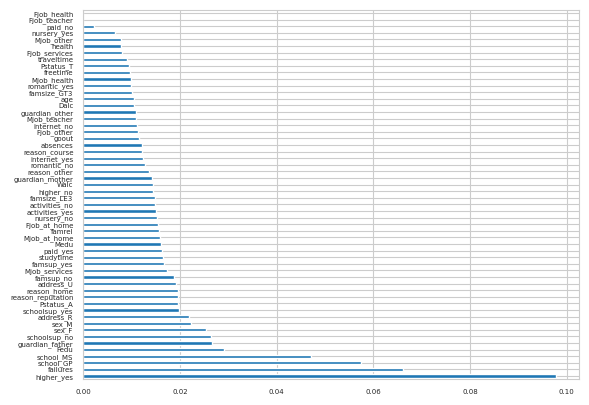

In [46]:
ranking = pd.Series(data=clf.feature_importances_,
                    index=X.columns)
ranking.sort_values(ascending=False).plot(kind="barh", fontsize=5)
print(ranking[ranking == 0.0].sort_values())

## Random Forest Classifier

In [47]:
param_grid = {
    'bootstrap':    [True, False],
    'ccp_alpha':  [0.0, 0.5],
    'criterion':    ['gini', 'entropy'],
    'n_estimators': [50, 100],
    'max_depth':    [4, 6],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'min_weight_fraction_leaf': [0.0, 0.5]
}

rf_model = RandomForestClassifier(random_state=42)
print(rf_model.get_params())

gs = GridSearchCV(rf_model, param_grid, scoring = 'accuracy', cv = 5)
gs.fit(X_train, y_train)

y_pred_rf = gs.predict(X_test_unb)

print("Random Forest Accuracy:", accuracy_score(y_test_unb, y_pred_rf))
print("\nRandom Forest Classification Report:\n", classification_report(y_test_unb, y_pred_rf))

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Random Forest Accuracy: 0.8846153846153846

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.71      0.75        31
           1       0.91      0.94      0.93        99

    accuracy                           0.88       130
   macro avg       0.85      0.82      0.84       130
weighted avg       0.88      0.88      0.88       130



In [48]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test_unb)
print("Random Forest Accuracy:", accuracy_score(y_test_unb, y_pred_rf))
print("\nRandom Forest Classification Report:\n", classification_report(y_test_unb, y_pred_rf))

Random Forest Accuracy: 0.9384615384615385

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.84      0.87        31
           1       0.95      0.97      0.96        99

    accuracy                           0.94       130
   macro avg       0.92      0.90      0.91       130
weighted avg       0.94      0.94      0.94       130



## Random Forest feature selection

[np.float64(0.0013211242829971196), np.float64(0.002195413512041396), np.float64(0.0033370963448016494), np.float64(0.003912450170885391), np.float64(0.003962610743687985), np.float64(0.004065263135584163), np.float64(0.004185982707702618), np.float64(0.004714163297290478), np.float64(0.005720122903725893), np.float64(0.006250674842025471), np.float64(0.0070062353522182715), np.float64(0.007396976814316903), np.float64(0.007916120258440821), np.float64(0.009116389219712993), np.float64(0.009520799615336922), np.float64(0.009578048653938931), np.float64(0.00981764427560478), np.float64(0.00984196706502758), np.float64(0.009914527183244374), np.float64(0.010187767832439444), np.float64(0.010252497026347163), np.float64(0.010442627342095154), np.float64(0.01057021796434528), np.float64(0.010789054846699073), np.float64(0.010987137160402984), np.float64(0.010987637370583685), np.float64(0.011668218804869583), np.float64(0.012516782074738955), np.float64(0.012840418631448707), np.float64(0.

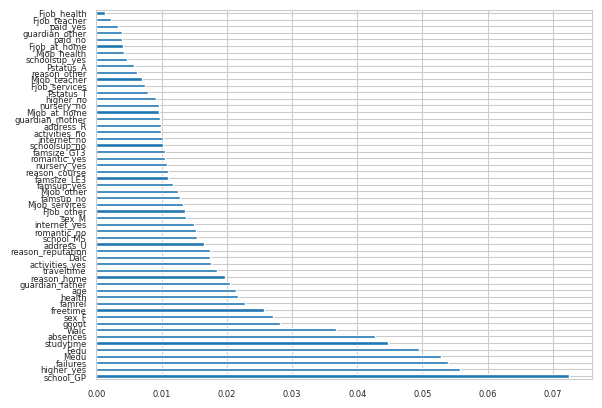

In [49]:
ranking = pd.Series(data=rf_model.feature_importances_,
                    index=X.columns)
ranking.sort_values(ascending=False).plot(kind="barh", fontsize=6)
print(sorted(ranking.values))

## SVC

In [50]:
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
#    'kernel': ['linear'],
    'gamma': ['scale', 'auto', 0.1, 1],
    'degree': [2, 3, 4],
    'coef0': [0.0, 1.0]
}

svc = SVC(random_state=42)

gs = GridSearchCV(svc, param_grid, scoring = 'accuracy', cv = 5)
gs.fit(X_train, y_train)

print(gs.best_estimator_)
y_pred_rf = gs.predict(X_test_unb)
print("SVC Accuracy:", accuracy_score(y_test_unb, y_pred_rf))
print("\nSVC Classification Report:\n", classification_report(y_test_unb, y_pred_rf))

SVC(C=0.1, degree=4, gamma='auto', kernel='poly', random_state=42)
SVC Accuracy: 0.9076923076923077

SVC Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.74      0.79        31
           1       0.92      0.96      0.94        99

    accuracy                           0.91       130
   macro avg       0.89      0.85      0.87       130
weighted avg       0.91      0.91      0.91       130



In [51]:
# Obter os coeficientes (importâncias relativas)
feature_importances = pd.Series(
    np.abs(gs.best_estimator_.coef_[0]),  # Usamos valor absoluto porque o sinal só indica direção
    index=X.columns
)
feature_importances.sort_values(ascending=False).plot(kind='barh', fontsize=6)

AttributeError: coef_ is only available when using a linear kernel

## Validação:

<br>

**Desempenho Observado:**

Após o treinamento de três algoritmos de aprendizado de máquina — XGBoost, Random Forest e SVM — realizamos testes sobre o conjunto de validação e analisamos duas métricas-chave: a acurácia (isto é, a proporção global de previsões corretas) e o macro-F1, que sintetiza, em um único número, o equilíbrio entre precisão e cobertura para as duas classes (“Aprovado” e “Reprovado”).

Tanto o XGBoost quanto o Random Forest atingiram 86 % de acerto e um macro-F1 igualmente próximo de 0,86, enquanto a SVM permaneceu em 78 % para ambas as métricas. Em termos práticos, isso significa que XGBoost e Random Forest acertaram, em média, 86 de cada 100 alunos, preservando um tratamento simétrico entre aprovados e reprovados. A SVM, por sua vez, apresentou nove erros adicionais em cada 100 previsões, com uma tendência ligeiramente maior de confundir as duas classes.

---

<br>

**Comparação Qualitativa:**

Embora o empate numérico entre XGBoost e Random Forest sugira equivalência, uma análise mais cuidadosa revela diferenças importantes.

O XGBoost exibiu o maior recall para a classe “Aprovado” (91 %, contra 90 % do Random Forest), o que reduz o risco de falsos “reprovados”. Além disso, por adotar um mecanismo de *boosting* regulado por parâmetros como *learning rate*, *subsample* e *gamma*, o XGBoost equilibra viés e variância de forma mais granular, mantendo boa generalização mesmo quando o conjunto de dados se expandir no futuro.

A SVM teve uma menor acurácia e mostrou-se menos amigável do ponto de vista de ajuste de hiperparâmetros, pois costuma ser sensível a ruído — especialmente quando o conjunto de atributos contém muitas variáveis dummies, como ocorre após a codificação one-hot.

---

<br>

**Conclusão:**

O XGBoost surge como a melhor escolha para o cenário atual: ele maximiza o acerto global, minimiza falsos reprovados e oferece mecanismos de explicação robustos.

O Random Forest constitui um bom plano B sempre que a simplicidade de treinamento e rapidez forem prioridades. Já a SVM pode ser descartada nesta fase, pois não atinge resultados que se destacam, nem fornece vantagens de escalabilidade ou performance compatíveis com os outros modelos.

Podemos concluir também que nem sempre o uso do gridSearch pode trazer resultados melhores que um simples "random_state", é necessário realizar testes para validar as melhores configurações dos classificadores, além dos pré-processamentos no dataset que melhoram a performance dos modelos.

# Final Steps (Submission)


1. Save this report as a Jupyter Notebook (`.ipynb`);
2. Export a copy of the report as a PDF file (`.pdf`);
3. Copy the dataset;
4. Compress all the files (the Jupyter Notebook, PDF, and dataset) into a single ZIP archive (`<your_team_name>.zip`);
5. Upload the ZIP file to AVA.